### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [8]:
data = pd.read_csv('data/coupons.csv')

In [9]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [10]:
data.info()
data.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64

3. Decide what to do about your missing data -- drop, replace, other...

In [11]:
#Car Missing Data assumption made by looking at data that OnStar collected car info, and replacement of null values with \"inability to collect car info via OnStar\" should be value for nulls",
#unique_value_locations = data.groupby('car').groups / Used to find out the index for the value to use in place of nulls
#print(unique_value_locations)
target_value_car = data.loc[[8277],'car'].values[0]
data['car'] = data['car'].fillna(target_value_car)


#Missing Data Bar
#Replace missing with 'never' as it this choice for the user was simply never selected by user
#unique_value_locations = data.groupby('Bar').groups
#print(unique_value_locations)
target_value_Bar = data.loc[[0],'Bar'].values[0]
data['Bar'] = data['Bar'].fillna(target_value_Bar)


#Missing Data for Caffee House
#unique_value_locations = data.groupby('CoffeeHouse').groups
#print(unique_value_locations)
target_value_CoffeeHouse = data.loc[[0],'CoffeeHouse'].values[0]
data['CoffeeHouse'] = data['CoffeeHouse'].fillna(target_value_CoffeeHouse)

#Missing Data for CarryAway
#unique_value_locations = data.groupby('CarryAway').groups
#print(unique_value_locations)

target_value_CarryAway = data.loc[[2293],'CarryAway'].values[0]
data['CarryAway'] = data['CarryAway'].fillna(target_value_CarryAway)

#Missing Data for Restaurant type 1
#unique_value_locations = data.groupby('RestaurantLessThan20').groups
#print(unique_value_locations)
target_value_RestaurantLessThan20 = data.loc[[990],'RestaurantLessThan20'].values[0]
data['RestaurantLessThan20'] = data['RestaurantLessThan20'].fillna(target_value_RestaurantLessThan20)

#Missing Data for Restaurant type 2
#unique_value_locations = data.groupby('Restaurant20To50').groups
#print(unique_value_locations)
target_value_Restaurant20To50= data.loc[[44], 'Restaurant20To50'].values[0]
data['Restaurant20To50'] = data['Restaurant20To50'].fillna(target_value_Restaurant20To50)
data.isna().sum()





destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
car                     0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64

4. What proportion of the total observations chose to accept the coupon?



In [13]:
y_equal_one_count = data['Y'].value_counts()[1]

# 2. Divide by the total number of records and multiply by 100
total_records = len(data)
percentage = (y_equal_one_count / total_records) * 100
print(f"Those that accepted coupon makes up {percentage:.2f} of the dataset")


Those that accepted coupon makes up 56.84 of the dataset


5. Use a bar plot to visualize the `coupon` column.

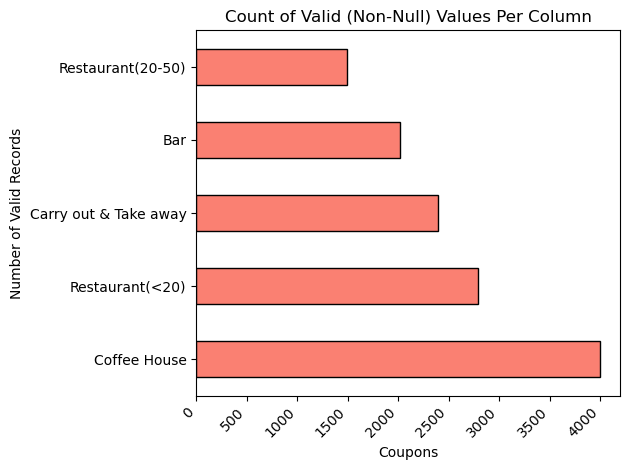

In [14]:
# 1. Get the count of non-null values for every column and plot
data['coupon'].value_counts().plot(kind='barh', color='salmon', edgecolor='black')
# 2. Add labels and layout tweaks
plt.title('Count of Valid (Non-Null) Values Per Column')
plt.xlabel('Coupons')
plt.ylabel('Number of Valid Records')
plt.xticks(rotation=45, ha='right')  # Tilts column names so they don't overlap
plt.tight_layout()                   # Prevents long labels from getting cut off
   


6. Use a histogram to visualize the temperature column.

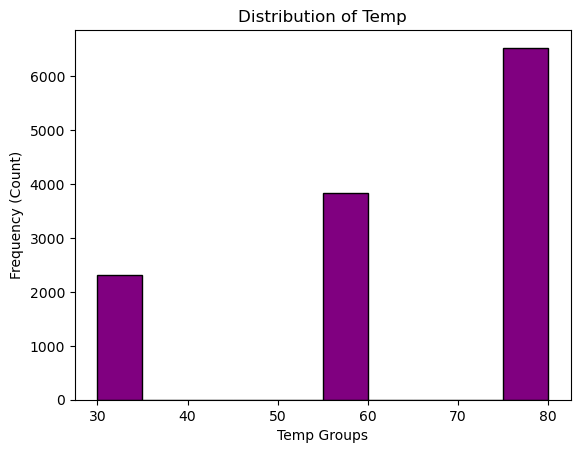

In [15]:
data['temperature'].plot(kind='hist', color='purple', edgecolor='black')
# 2. Add labels
plt.title('Distribution of Temp')
plt.xlabel('Temp Groups')
plt.ylabel('Frequency (Count)')
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [16]:
bar_data = data[data['coupon'] == 'Bar'].copy()
bar_data.head(10)
#bar_data.info()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,never,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1
39,Work,Alone,Sunny,55,7AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,1,1,0,1,1
46,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,0,1,0
57,Home,Alone,Sunny,55,6PM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,0,0,1,0,0
61,Work,Alone,Sunny,55,7AM,Bar,1d,Male,46,Single,...,4~8,1~3,1~3,never,1,1,1,0,1,0
75,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Male,46,Married partner,...,1~3,1~3,1~3,less1,1,1,0,0,1,1


2. What proportion of bar coupons were accepted?


In [40]:
y_equal_one_count = bar_data['Y'].value_counts()[1]
# 1. Divide by the total number of records and multiply by 100
total_records = len(bar_data)
percentage = (y_equal_one_count / total_records) * 100
print(f"Those that accepted bar coupon make up {percentage:.2f}% of the dataset.")

Those that accepted bar coupon make up 41.00% of the dataset.


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [55]:
# Goal: Count records where Bar is NOT ('4~8' or 'gt8') AND Y == 1
# 1. Define the Bar values to exclude
excluded_freq_1 = ['4~8', 'gt8']
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_1 = \
    ((~bar_data['Bar'].isin(excluded_freq_1)) & \
    (bar_data['Y'] == 1)).sum()

# 3. Divide by the total number of records and multiply by 100
total_records_1 = len(bar_data)
percentage_1 = (matching_count_1 / total_records_1) * 100
print(f"Those that accepted bar coupon and went 3 or fewer times per month make up {percentage_1:.2f}% of the dataset.")
#####
      
# Goal: Count records where Bar is NOT ('never' or '1~3' or 'less1') AND Y == 1
# 1. Define the Bar values to exclude
excluded_freq_2 = ['never', '1~3','less1']
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_2 =  \
    ((~bar_data['Bar'].isin(excluded_freq_2)) & \
    (bar_data['Y'] == 1)).sum()
# 3. Divide by the total number of records and multiply by 100
total_records_2 = len(bar_data)
percentage_2 = (matching_count_2 / total_records_2) * 100
print(f"Those that accepted bar coupon and went more than 3 times per month make up {percentage_2:.2f}% of the dataset.")


Those that accepted bar coupon and went 3 or fewer times per month make up 33.42% of the dataset.
Those that accepted bar coupon and went more than 3 times per month make up 7.59% of the dataset.


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [57]:
# Goal: Count records where Bar is NOT ('less1','never') AND Y == 1 AND AGE > 25
# 1. Define the Bar values to exclude
excluded_freq_3 = ['less1','never']
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_3 = (
    (~bar_data['Bar'].isin(excluded_freq_3)) & 
    ((bar_data['age']) > '25') &
    (bar_data['Y'] == 1)
     ).sum()
total_records_1 = len(bar_data)
percentage_3 = (matching_count_3 / total_records_1) * 100
print(f"Those that accepted bar coupon and went more than once per month and were over 25 yrs old make up {percentage_3:.2f}% of the dataset.")
   
# Goal: Count records where Bar is NOT ('less1','never') AND Y == 1 AND AGE < 25
# 1. Define the Bar values to exclude
excluded_freq_4 = ['less1','never']
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_4 = (
    (~bar_data['Bar'].isin(excluded_freq_4)) &
    ((bar_data['age']) < '25') &
    (bar_data['Y'] == 1)
    ).sum()
total_records_1 = len(bar_data)
percentage_4 = (matching_count_4 / total_records_1) * 100
print(f"Those that accepted bar coupon and went more than once per month and were under 25 yrs old make up {percentage_4:.2f}% of the dataset.")

Those that accepted bar coupon and went more than once per month and were over 25 yrs old make up 14.68% of the dataset.
Those that accepted bar coupon and went more than once per month and were under 25 yrs old make up 5.65% of the dataset.


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [58]:
# Goal: Count records where Bar is NOT ('less1','never') AND Y == 1 AND Passengers not a kid and had occupations not farming, fishing, or forestry
# 1. Define the Bar values to exclude
excluded_freq_5 = ['less1','never']
excluded_freq_6 = ['Kids(s)']
excluded_freq_7 = ['Farming Fishing & Forestry']
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_5 = (
    (~bar_data['Bar'].isin(excluded_freq_5)) & 
    (~bar_data['passanger'].isin(excluded_freq_6)) &
    (~bar_data['occupation'].isin(excluded_freq_6)) &
    (bar_data['Y'] == 1)
    ).sum()
total_records_1 = len(bar_data)
percentage_5 = (matching_count_5 / total_records_1) * 100
print(f"Those that accepted bar coupon and went more than once per month and did not have kids as passengers and were not working in Fishing/Forestry/Farming make up {percentage_5:.2f}% of the dataset.")


Those that accepted bar coupon and went more than once per month and did not have kids as passengers and were not working in Fishing/Forestry/Farming make up 20.33% of the dataset.


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [64]:
#Goal: Count records where Bar is NOT ('less1','never') AND Y == 1 AND Passengers not a kid and were not widowed
# 1. Define the Bar values to exclude
excluded_freq_8 = ['less1','never']
excluded_freq_9 = ['Kids(s)']
excluded_freq_10 = ['Widowed']
    
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_6 = (
    (~bar_data['Bar'].isin(excluded_freq_8)) & 
    (~bar_data['passanger'].isin(excluded_freq_9)) &
    (~bar_data['maritalStatus'].isin(excluded_freq_10)) &
    (bar_data['Y'] == 1)
    ).sum()
total_records_1 = len(bar_data)
percentage_6 = (matching_count_6 / total_records_1) * 100
print(f"Those that accepted bar coupon and went more than once per month and did not have kids as passengers and were not widowed make up {percentage_6:.2f}% of the dataset.")

###########

#Goal: Count records where Bar is NOT ('less1','never') AND Y == 1 AND under age of 30
# 1. Define the Bar values to exclude
excluded_freq_11 = ['less1','never']
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_7 = (
    (~bar_data['Bar'].isin(excluded_freq_11)) & 
    ((bar_data['age']) < '30') &
    (bar_data['Y'] == 1)
    ).sum()
total_records_1 = len(bar_data)
percentage_7 = (matching_count_7 / total_records_1) * 100
print(f"Those that accepted bar coupon and went more than once per month and were less than 30 yrs old make up {percentage_7:.2f}% of the dataset.")

#Goal: Count records where patrons visit cheap restaurants more 4 x per month AND earn less than $50k
# 1. Define the Bar values to exclude
excluded_freq_12 = ['less1','never','1~3']
# 2. Combine both conditions with & and use .sum() to count the matching rows
matching_count_8 = (
    (~bar_data['RestaurantLessThan20'].isin(excluded_freq_12)) & 
    ((bar_data['income']) < '50000') &
    (bar_data['Y'] == 1)
    ).sum()
total_records_1 = len(bar_data)
percentage_8 = (matching_count_8 / total_records_1) * 100
print(f"Those that accepted bar coupon and went more than 4x / month to cheap restaurants and whose income was less than $50k  make up {percentage_8:.2f}% of the dataset.")

print(f"Those that accepted bar coupon and went more than 4x / month to cheap restaurants and whose income was less than $50k proabably should be 9% of the dataset as I compute it outside this code.")


Those that accepted bar coupon and went more than once per month and did not have kids as passengers and were not widowed make up 20.33% of the dataset.
Those that accepted bar coupon and went more than once per month and were less than 30 yrs old make up 12.15% of the dataset.
Those that accepted bar coupon and went more than 4x / month to cheap restaurants and whose income was less than $50k  make up 14.63% of the dataset.
Those that accepted bar coupon and went more than 4x / month to cheap restaurants and whose income was less than $50k proabably should be 9% of the dataset as I compute it outside this code.


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [70]:
print(f"Of those that accepted bar coupons, I hypothesize that a different passenger and/or marital status, etc, selection would lead me to the lion share of coupon conversions (because married folks with no kids only made up ~20% of bar coupons).")
print(f"I hypothesize that bar coupons falls off exponentially somewhere between the ages of 21-24, as 25-year-olds and older are 9 percentage points above those under 25 years old in terms of accepting coupons.")
print(f"I hypothesize that of the ~40% of those who accepted the bar coupons, the majority of these folks were apt to convert just a few times per month. The frequency of the sending of coupons should take into account this kind of info per demographic group.")

Of those that accepted bar coupons, I hypothesize that a different passenger and/or marital status, etc, selection would lead me to the lion share of coupon conversions (because married folks with no kids only made up ~20% of bar coupons).
I hypothesize that bar coupons falls off exponentially somewhere between the ages of 21-24, as 25-year-olds and older are 9 percentage points above those under 25 years old in terms of accepting coupons.
I hypothesize that of the ~40% of those who accepted the bar coupons, the majority of these folks were apt to convert just a few times per month. The frequency of the sending of coupons should take into account this kind of info per demographic group.


### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  